<a href="https://colab.research.google.com/github/v-ohamuo/looped-transformer-optimizers/blob/main/looped_optimizers_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Optimizers from scratch on a looped (weight-tied) transformer

**What this notebook does**
1. Writes SGD, momentum, Adam and a simple Muon-style optimizer in plain PyTorch (no `torch.optim`).
2. Checks that my versions match PyTorch's built-in ones on a small problem.
3. Trains a tiny transformer that re-uses ONE block N times (a "looped" model) on modular addition.
4. Compares the optimizers: loss curves + gradient norms (stability).

**Task:** given two numbers a and b, predict (a + b) mod 17.

Run the cells

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("using", device)

using cpu


## Part 1: the optimizers

Every optimizer here has the same two methods as PyTorch's: `zero_grad()` and `step()`.
`step()` is where the update rule lives.

In [ ]:
class MySGD:
    # Plain gradient descent: weight = weight - lr * gradient
    def __init__(self, params, lr=0.1):
        self.params = list(params)
        self.lr = lr

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    @torch.no_grad()  # we're editing weights directly, so autograd shouldn't track it
    def step(self):
        for p in self.params:
            if p.grad is None:
                continue
            p -= self.lr * p.grad


class MyMomentum:
    # SGD + momentum: keep a running "velocity" so updates keep going in a consistent direction.
    # buffer = mu * buffer + grad ;  weight = weight - lr * buffer
    def __init__(self, params, lr=0.1, mu=0.9):
        self.params = list(params)
        self.lr, self.mu = lr, mu
        self.buf = [torch.zeros_like(p) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    @torch.no_grad()
    def step(self):
        for p, b in zip(self.params, self.buf):
            if p.grad is None:
                continue
            b.mul_(self.mu).add_(p.grad)
            p -= self.lr * b


class MyAdam:
    # Adam: track the average gradient (m) and the average squared gradient (v),
    # then divide, so every weight gets its own step size.
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = list(params)
        self.lr, self.b1, self.b2, self.eps = lr, betas[0], betas[1], eps
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0  # step counter, needed for bias correction

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    @torch.no_grad()
    def step(self):
        self.t += 1
        for p, m, v in zip(self.params, self.m, self.v):
            if p.grad is None:
                continue
            g = p.grad
            m.mul_(self.b1).add_(g, alpha=1 - self.b1)          # average of gradients
            v.mul_(self.b2).addcmul_(g, g, value=1 - self.b2)   # average of squared gradients
            m_hat = m / (1 - self.b1 ** self.t)                 # bias correction (m and v start at 0)
            v_hat = v / (1 - self.b2 ** self.t)
            p -= self.lr * m_hat / (v_hat.sqrt() + self.eps)

### Muon-style update

Idea: for a weight *matrix*, take the momentum, then **orthogonalize** it, which means pushing all its
singular values towards 1. The update then moves the matrix equally in every direction instead of
being dominated by a few big ones. The orthogonalization is done with a few Newton-Schulz iterations
(only matrix multiplies, so it's cheap).

Rules I'm following (these are how Muon is normally used):
- Muon only for **2D weight matrices** in the hidden layers.
- Everything else (embeddings, output head, norms) uses Adam.

In [ ]:
def newton_schulz(G, steps=5):
    # Approximately replaces G by the nearest orthogonal-ish matrix (singular values ~ 1).
    # The a, b, c numbers are the tuned constants from the public Muon implementation.
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + 1e-7)           # scale down so the iteration is stable
    flip = G.shape[0] > G.shape[1]      # work with a "wide" matrix (rows <= cols)
    if flip:
        X = X.T
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * (A @ A)
        X = a * X + B @ X
    if flip:
        X = X.T
    return X


class MyMuon:
    # muon_params: list of 2D weight matrices -> momentum + orthogonalized update
    # adam_params: everything else -> handled by my own Adam
    def __init__(self, muon_params, adam_params, lr=0.02, mu=0.95, adam_lr=1e-3):
        self.muon_params = list(muon_params)
        self.lr, self.mu = lr, mu
        self.buf = [torch.zeros_like(p) for p in self.muon_params]
        self.adam = MyAdam(adam_params, lr=adam_lr)
        self.params = self.muon_params + self.adam.params

    def zero_grad(self):
        for p in self.params:
            p.grad = None

    @torch.no_grad()
    def step(self):
        for p, b in zip(self.muon_params, self.buf):
            if p.grad is None:
                continue
            b.mul_(self.mu).add_(p.grad)
            update = newton_schulz(b)
            # scale so tall and wide matrices get a similar update size
            update = update * math.sqrt(max(1, p.shape[0] / p.shape[1]))
            p -= self.lr * update
        self.adam.step()

## Part 2: check my optimizers against PyTorch

Same tiny network, same starting weights, same data, 50 full-batch steps.
If my update rules are right, the final weights should be basically identical (difference around 1e-6 or smaller).
PyTorch has no matching Muon to compare against, so for Muon I check a different property:
the update should have singular values close to 1.

In [ ]:
def make_mlp():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(4, 16), nn.Tanh(), nn.Linear(16, 1)).double()  # double = fewer rounding errors

torch.manual_seed(1)
X = torch.randn(64, 4).double()
y = torch.randn(64, 1).double()

def train_steps(model, opt, n=50):
    for _ in range(n):
        opt.zero_grad()
        loss = F.mse_loss(model(X), y)
        loss.backward()
        opt.step()

def max_diff(m1, m2):
    return max((a - b).abs().max().item() for a, b in zip(m1.parameters(), m2.parameters()))

pairs = {
    "SGD":      (lambda p: MySGD(p, lr=0.1),               lambda p: torch.optim.SGD(p, lr=0.1)),
    "Momentum": (lambda p: MyMomentum(p, lr=0.05, mu=0.9), lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
    "Adam":     (lambda p: MyAdam(p, lr=1e-2),             lambda p: torch.optim.Adam(p, lr=1e-2)),
}
for name, (mine, theirs) in pairs.items():
    m1, m2 = make_mlp(), make_mlp()
    train_steps(m1, mine(m1.parameters()))
    train_steps(m2, theirs(m2.parameters()))
    d = max_diff(m1, m2)
    print(f"{name:9s} max weight difference = {d:.2e}  ->", "OK" if d < 1e-6 else "MISMATCH, check the code")

# Muon sanity check: orthogonalizing a random matrix should push singular values near 1
G = torch.randn(32, 64)
S = torch.linalg.svdvals(newton_schulz(G))
print("Muon: singular values after Newton-Schulz are between", round(S.min().item(), 2), "and", round(S.max().item(), 2))

SGD       max weight difference = 1.11e-16  -> OK
Momentum  max weight difference = 1.11e-16  -> OK
Adam      max weight difference = 4.44e-16  -> OK
Muon: singular values after Newton-Schulz are between 0.68 and 1.13


## Part 3: the looped transformer

One transformer block (attention + MLP) whose weights are **shared**. I run the same block `n_loops` times
on the same sequence, so more loops = more "thinking steps" but no extra parameters.

Input is 3 tokens: `[a, b, =]`. The model reads its answer from the last position.

In [ ]:
P = 17  # we do arithmetic mod 17

# All possible (a, b) pairs. Token id P is the "=" symbol.
a = torch.arange(P).repeat_interleave(P)
b = torch.arange(P).repeat(P)
inputs = torch.stack([a, b, torch.full_like(a, P)], dim=1)
targets = (a + b) % P

# Fixed random 70/30 split so every run uses the same data
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(inputs), generator=g)
n_train = int(0.7 * len(inputs))
Xtr, ytr = inputs[perm[:n_train]].to(device), targets[perm[:n_train]].to(device)
Xte, yte = inputs[perm[n_train:]].to(device), targets[perm[n_train:]].to(device)
print("train examples:", len(Xtr), " test examples:", len(Xte))

train examples: 202  test examples: 87


In [ ]:
class LoopedTransformer(nn.Module):
    def __init__(self, vocab=P + 1, d=64, heads=4, n_loops=4):
        super().__init__()
        self.d, self.heads, self.n_loops = d, heads, n_loops
        self.tok_emb = nn.Embedding(vocab, d)        # token -> vector
        self.pos_emb = nn.Embedding(3, d)            # position -> vector
        # ---- the ONE shared block ----
        self.ln1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False)   # makes queries, keys, values
        self.proj = nn.Linear(d, d, bias=False)      # mixes attention heads back together
        self.ln2 = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 4 * d, bias=False)   # MLP up
        self.fc2 = nn.Linear(4 * d, d, bias=False)   # MLP down
        # ------------------------------
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, P, bias=False)      # vector -> scores for each answer 0..P-1

    def block(self, x):
        B, T, D = x.shape
        # attention
        q, k, v = self.qkv(self.ln1(x)).chunk(3, dim=-1)
        q, k, v = [t.view(B, T, self.heads, D // self.heads).transpose(1, 2) for t in (q, k, v)]
        att = F.scaled_dot_product_attention(q, k, v)   # no causal mask: all 3 tokens can see each other
        att = att.transpose(1, 2).reshape(B, T, D)
        x = x + self.proj(att)                          # residual connection
        # MLP
        x = x + self.fc2(F.gelu(self.fc1(self.ln2(x))))
        return x

    def forward(self, tokens):
        x = self.tok_emb(tokens) + self.pos_emb(torch.arange(tokens.shape[1], device=tokens.device))
        for _ in range(self.n_loops):   # <- the loop: SAME weights every time
            x = self.block(x)
        return self.head(self.ln_f(x[:, -1]))   # read the answer from the last token

m = LoopedTransformer()
print("parameters:", sum(p.numel() for p in m.parameters()))

parameters: 51968


## Part 4: compare the optimizers

For each optimizer and each loop count (1, 4, 8) I train on 3 random seeds and record the loss and the
gradient norm at every step. A gradient norm that spikes or explodes means the training is unstable.

Learning rates below are reasonable starting guesses, not tuned. Changing them is a good experiment.

In [ ]:
def make_optimizer(name, model):
    if name == "SGD":
        return MySGD(model.parameters(), lr=0.05)
    if name == "Momentum":
        return MyMomentum(model.parameters(), lr=0.02, mu=0.9)
    if name == "Adam":
        return MyAdam(model.parameters(), lr=3e-3)
    if name == "Muon":
        # hidden 2D matrices -> Muon; embeddings, output head, norms -> Adam
        muon, other = [], []
        for n, p in model.named_parameters():
            if p.ndim == 2 and "emb" not in n and "head" not in n:
                muon.append(p)
            else:
                other.append(p)
        return MyMuon(muon, other, lr=0.02, adam_lr=3e-3)

def run(opt_name, n_loops, seed, steps=400):
    torch.manual_seed(seed)
    model = LoopedTransformer(n_loops=n_loops).to(device)
    opt = make_optimizer(opt_name, model)
    losses, gnorms = [], []
    for step in range(steps):
        loss = F.cross_entropy(model(Xtr), ytr)
        if not torch.isfinite(loss):          # training blew up (NaN / inf)
            break
        opt.zero_grad()
        loss.backward()
        gn = torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters() if p.grad is not None))
        losses.append(loss.item())
        gnorms.append(gn.item())
        opt.step()
    diverged = len(losses) < steps
    # pad with NaN so every run has the same length
    losses += [float("nan")] * (steps - len(losses))
    gnorms += [float("nan")] * (steps - len(gnorms))
    with torch.no_grad():
        test_acc = (model(Xte).argmax(-1) == yte).float().mean().item()
    return torch.tensor(losses), torch.tensor(gnorms), test_acc, diverged

In [ ]:
opt_names = ["SGD", "Momentum", "Adam", "Muon"]
loop_counts = [1, 4, 8]
seeds = [0, 1, 2]

results = {}   # (optimizer, loops) -> list of (losses, gnorms, test_acc, diverged), one per seed
for o in opt_names:
    for L in loop_counts:
        results[(o, L)] = [run(o, L, s) for s in seeds]
        print("done", o, "loops =", L)

done SGD loops = 1
done SGD loops = 4
done SGD loops = 8
done Momentum loops = 1
done Momentum loops = 4
done Momentum loops = 8
done Adam loops = 1
done Adam loops = 4
done Adam loops = 8
done Muon loops = 1
done Muon loops = 4
done Muon loops = 8


## Results: loss curves (mean over seeds, shaded = min to max)

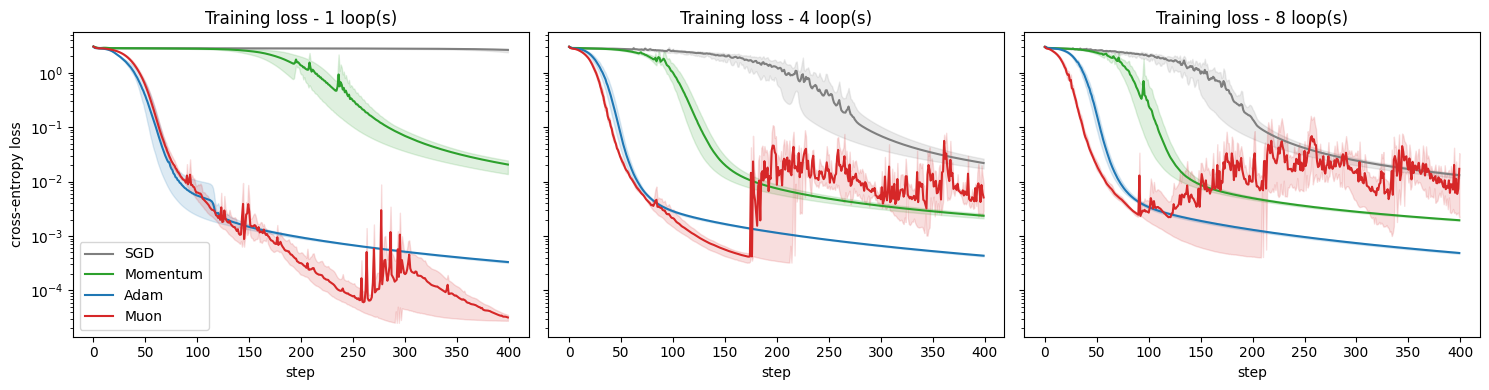

In [ ]:
colors = {"SGD": "tab:gray", "Momentum": "tab:green", "Adam": "tab:blue", "Muon": "tab:red"}

def plot_metric(index, title, ylabel, logy=True):
    fig, axes = plt.subplots(1, len(loop_counts), figsize=(15, 4), sharey=True)
    for ax, L in zip(axes, loop_counts):
        for o in opt_names:
            runs = torch.stack([r[index] for r in results[(o, L)]])   # seeds x steps
            mean = runs.mean(0)   # becomes NaN if any seed diverged; that is intentional (shows instability)
            ax.plot(mean, label=o, color=colors[o])
            ax.fill_between(range(runs.shape[1]), runs.nan_to_num(1e9).min(0).values,
                            runs.nan_to_num(0).max(0).values, color=colors[o], alpha=0.15)
        ax.set_title(f"{title} - {L} loop(s)")
        ax.set_xlabel("step")
        if logy:
            ax.set_yscale("log")
    axes[0].set_ylabel(ylabel)
    axes[0].legend()
    plt.tight_layout()
    plt.show()

plot_metric(0, "Training loss", "cross-entropy loss")

## Results: gradient norm (spikes = unstable)

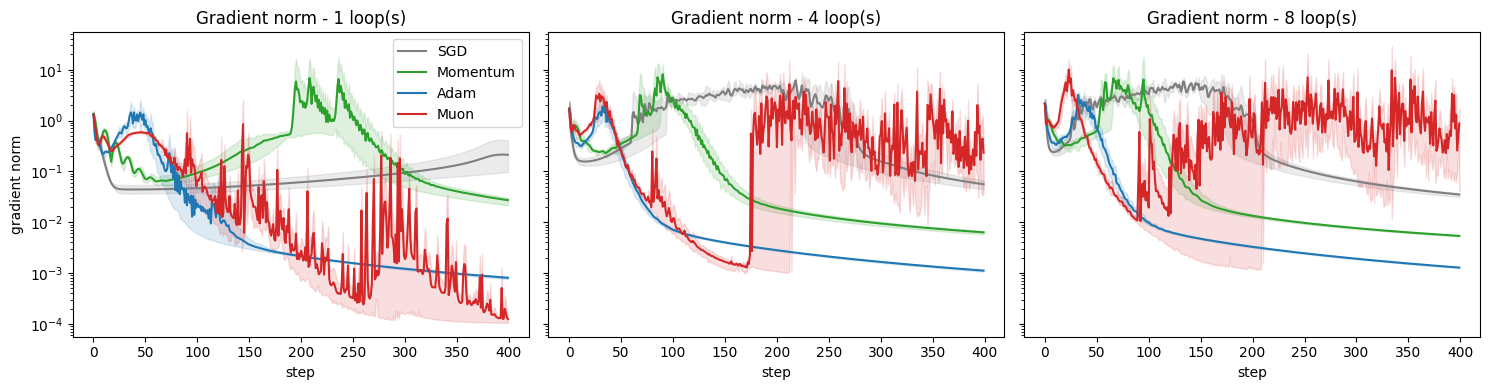

In [ ]:
plot_metric(1, "Gradient norm", "gradient norm")

## Results: summary table

In [ ]:
print(f"{'optimizer':10s} {'loops':>5s} {'final loss':>11s} {'test acc':>9s} {'diverged':>9s}")
for o in opt_names:
    for L in loop_counts:
        rs = results[(o, L)]
        finals = [r[0][~torch.isnan(r[0])][-1].item() if (~torch.isnan(r[0])).any() else float("nan") for r in rs]
        print(f"{o:10s} {L:5d} {sum(finals)/len(finals):11.4f} "
              f"{sum(r[2] for r in rs)/len(rs):9.2f} {sum(r[3] for r in rs):>6d}/{len(rs)}")

optimizer  loops  final loss  test acc  diverged
SGD            1      2.6229      0.00      0/3
SGD            4      0.0219      0.45      0/3
SGD            8      0.0131      0.33      0/3
Momentum       1      0.0206      0.41      0/3
Momentum       4      0.0024      0.38      0/3
Momentum       8      0.0019      0.23      0/3
Adam           1      0.0003      0.15      0/3
Adam           4      0.0004      0.18      0/3
Adam           8      0.0005      0.07      0/3
Muon           1      0.0000      0.59      0/3
Muon           4      0.0051      0.28      0/3
Muon           8      0.0171      0.30      0/3


## What to write about (fill this in with your own words after running)

- Which optimizer got the lowest training loss? Was it the same for 1, 4 and 8 loops?
- Did gradient norms change with more loops? (Tied weights add up gradients from every loop.)
- Did any run diverge (NaN)? Which optimizer and which loop count?
- Test accuracy vs training loss: is the model memorizing or actually learning the rule?
- Limitations: tiny model, 3 seeds, learning rates not tuned.

## Next step (later): loop vs depth
Compare this looped model (1 shared block repeated N times) against a normal model with N *different*
blocks. Same compute, but N times more parameters. Which learns better on this task?

---
# Part 5: loop vs depth

**Question:** does reusing ONE block N times work as well as having N DIFFERENT blocks?

```
Looped, N=4:  input -> [Block A] -> [Block A] -> [Block A] -> [Block A] -> output   (same weights)
Depth,  N=4:  input -> [Block A] -> [Block B] -> [Block C] -> [Block D] -> output   (different weights)
```

Both do N block passes per prediction (same compute). The difference is the number of parameters:
the looped model stays at 51,968, the depth model grows with N.

I use the same task, data, optimizers, learning rates, seeds and steps as before, so the only change is the model.
Run the cells in order. The looped results from Part 4 must already be in memory (run Part 4 first).

In [ ]:
# One ordinary transformer block with its OWN weights
class Block(nn.Module):
    def __init__(self, d=64, heads=4):
        super().__init__()
        self.heads = heads
        self.ln1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.proj = nn.Linear(d, d, bias=False)
        self.ln2 = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, 4 * d, bias=False)
        self.fc2 = nn.Linear(4 * d, d, bias=False)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).chunk(3, dim=-1)
        q, k, v = [t.view(B, T, self.heads, D // self.heads).transpose(1, 2) for t in (q, k, v)]
        att = F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(B, T, D)
        x = x + self.proj(att)                              # residual connection
        return x + self.fc2(F.gelu(self.fc1(self.ln2(x))))  # MLP + residual


# N DIFFERENT blocks, each used once (a normal deep transformer)
class DepthTransformer(nn.Module):
    def __init__(self, vocab=P + 1, d=64, heads=4, n_blocks=4):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, d)
        self.pos_emb = nn.Embedding(3, d)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(n_blocks)])  # separate weights each
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, P, bias=False)

    def forward(self, tokens):
        x = self.tok_emb(tokens) + self.pos_emb(torch.arange(tokens.shape[1], device=tokens.device))
        for blk in self.blocks:      # each blk has DIFFERENT weights (unlike the looped model)
            x = blk(x)
        return self.head(self.ln_f(x[:, -1]))

# parameter counts: expect about 51,968 / 200,192 / 397,824
print({n: sum(p.numel() for p in DepthTransformer(n_blocks=n).parameters()) for n in [1, 4, 8]})

{1: 51968, 4: 200192, 8: 397824}


In [ ]:
# same as run() from Part 4, but builds the depth model instead
def run_depth(opt_name, n_blocks, seed, steps=400):
    torch.manual_seed(seed)
    model = DepthTransformer(n_blocks=n_blocks).to(device)
    opt = make_optimizer(opt_name, model)   # the same optimizer setup as before
    losses, gnorms = [], []
    for step in range(steps):
        loss = F.cross_entropy(model(Xtr), ytr)
        if not torch.isfinite(loss):
            break
        opt.zero_grad()
        loss.backward()
        gn = torch.sqrt(sum((p.grad ** 2).sum() for p in model.parameters() if p.grad is not None))
        losses.append(loss.item())
        gnorms.append(gn.item())
        opt.step()
    diverged = len(losses) < steps
    losses += [float("nan")] * (steps - len(losses))
    gnorms += [float("nan")] * (steps - len(gnorms))
    with torch.no_grad():
        test_acc = (model(Xte).argmax(-1) == yte).float().mean().item()
    return torch.tensor(losses), torch.tensor(gnorms), test_acc, diverged

results_loop = results     # keep the looped results from Part 4 safe
results_depth = {}         # (optimizer, N blocks) -> list of runs, one per seed
for o in opt_names:
    for N in loop_counts:
        results_depth[(o, N)] = [run_depth(o, N, s) for s in seeds]
        print("done", o, "blocks =", N)

done SGD blocks = 1
done SGD blocks = 4
done SGD blocks = 8
done Momentum blocks = 1
done Momentum blocks = 4
done Momentum blocks = 8
done Adam blocks = 1
done Adam blocks = 4
done Adam blocks = 8
done Muon blocks = 1
done Muon blocks = 4
done Muon blocks = 8


## Loop vs depth: loss curves (solid = looped, dashed = depth)

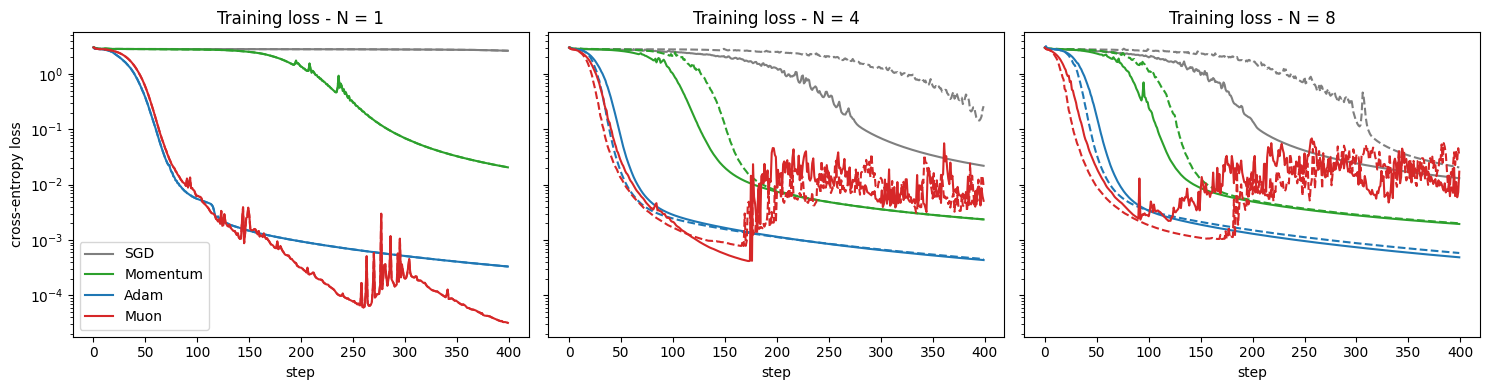

In [ ]:
def plot_compare(index, title, ylabel):
    fig, axes = plt.subplots(1, len(loop_counts), figsize=(15, 4), sharey=True)
    for ax, N in zip(axes, loop_counts):
        for o in opt_names:
            lo = torch.stack([r[index] for r in results_loop[(o, N)]]).mean(0)
            de = torch.stack([r[index] for r in results_depth[(o, N)]]).mean(0)
            ax.plot(lo, color=colors[o], label=o)
            ax.plot(de, color=colors[o], linestyle="--")
        ax.set_yscale("log")
        ax.set_title(f"{title} - N = {N}")
        ax.set_xlabel("step")
    axes[0].set_ylabel(ylabel)
    axes[0].legend()
    plt.tight_layout()
    plt.show()

plot_compare(0, "Training loss", "cross-entropy loss")

## Loop vs depth: gradient norm (solid = looped, dashed = depth)

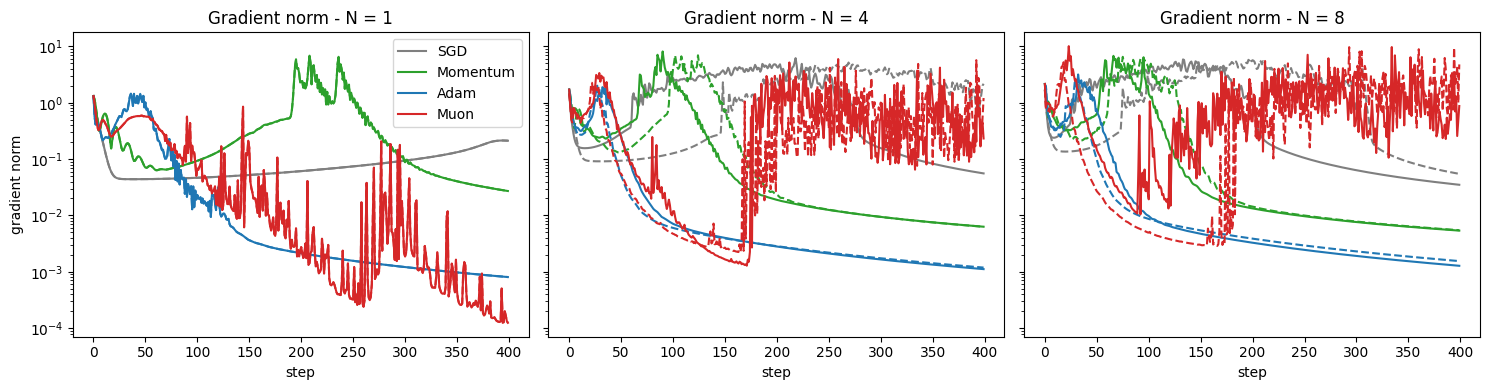

In [ ]:
plot_compare(1, "Gradient norm", "gradient norm")

## Loop vs depth: summary table

In [ ]:
def final_loss(runs):
    vals = []
    for r in runs:
        ok = r[0][~torch.isnan(r[0])]
        vals.append(ok[-1].item() if len(ok) else float("nan"))
    return sum(vals) / len(vals)

def mean_acc(runs):
    return sum(r[2] for r in runs) / len(runs)

print(f"{'optimizer':10s} {'N':>2s} | {'loop loss':>10s} {'loop acc':>9s} | {'depth loss':>10s} {'depth acc':>9s} | {'depth diverged':>14s}")
for o in opt_names:
    for N in loop_counts:
        lo, de = results_loop[(o, N)], results_depth[(o, N)]
        print(f"{o:10s} {N:2d} | {final_loss(lo):10.4f} {mean_acc(lo):9.2f} | "
              f"{final_loss(de):10.4f} {mean_acc(de):9.2f} | {sum(r[3] for r in de):>12d}/3")

optimizer   N |  loop loss  loop acc | depth loss depth acc | depth diverged
SGD         1 |     2.6229      0.00 |     2.6229      0.00 |            0/3
SGD         4 |     0.0219      0.45 |     0.2616      0.13 |            0/3
SGD         8 |     0.0131      0.33 |     0.0205      0.25 |            0/3
Momentum    1 |     0.0206      0.41 |     0.0206      0.41 |            0/3
Momentum    4 |     0.0024      0.38 |     0.0024      0.37 |            0/3
Momentum    8 |     0.0019      0.23 |     0.0020      0.28 |            0/3
Adam        1 |     0.0003      0.15 |     0.0003      0.15 |            0/3
Adam        4 |     0.0004      0.18 |     0.0005      0.31 |            0/3
Adam        8 |     0.0005      0.07 |     0.0006      0.39 |            0/3
Muon        1 |     0.0000      0.59 |     0.0000      0.59 |            0/3
Muon        4 |     0.0051      0.28 |     0.0094      0.34 |            0/3
Muon        8 |     0.0171      0.30 |     0.0337      0.30 |            0/3